# Terra Signal — United Kingdom
## Reproducible country model
NASA POWER monthly observations, 2011–2025. This notebook reproduces the project’s three-feature Isolation Forest. Soil wetness is not NDVI; fire is not included. Data are coarse sampled grid locations, not complete national coverage.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import statistics
from scipy.stats import norm
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest
import sklearn, joblib
import matplotlib.pyplot as plt
assert sklearn.__version__ == '1.8.0', 'Use the project scikit-learn version'
ROOT = Path.cwd() if (Path.cwd() / 'datasets').exists() else Path.cwd().parent
SLUG = 'united_kingdom'
raw = pd.read_csv(ROOT / 'datasets' / (SLUG + '.csv'))
raw['year'] = raw.date.str[:4].astype(int)
raw['month'] = raw.date.str[5:].astype(int)
print('Observations:', len(raw), 'Grid cells:', raw.cell_id.nunique())
assert not raw[['temperature_c','precipitation_mm_day','root_zone_soil_wetness']].isna().any().any()
assert not raw.duplicated(['cell_id','date']).any()
raw.head()

Observations: 360 Grid cells: 2


,country,area,cell_id,lat,lon,date,temperature_c,precipitation_mm_day,root_zone_soil_wetness,year,month
0,United Kingdom,Shropshire,G5-L0525N-O0025W,52.5,-2.5,2011-01,2.09,2.00,0.70,2011,1
1,United Kingdom,Shropshire,G5-L0525N-O0025W,52.5,-2.5,2011-02,5.28,2.31,0.72,2011,2
2,United Kingdom,Shropshire,G5-L0525N-O0025W,52.5,-2.5,2011-03,5.81,0.51,0.72,2011,3
3,United Kingdom,Shropshire,G5-L0525N-O0025W,52.5,-2.5,2011-04,10.73,0.48,0.69,2011,4
4,United Kingdom,Shropshire,G5-L0525N-O0025W,52.5,-2.5,2011-05,11.16,1.85,0.65,2011,5


## Seasonal feature engineering
Fit monthly baselines for each cell using 2011–2020 only. Temperature uses population standard deviation (fallback 0.5 when zero); soil wetness uses percentage deviation; rainfall uses the empirical midrank percentile, clipped to 0.5–99.5 before the normal quantile transform.

In [2]:
parts = []
for (cell, month), group in raw.groupby(['cell_id','month']):
    base = group[group.year <= 2020]
    assert len(base) == 10
    tm = statistics.fmean(base.temperature_c)
    ts = statistics.pstdev(base.temperature_c) or .5
    wm = statistics.fmean(base.root_zone_soil_wetness)
    p = base.precipitation_mm_day.tolist()
    out = group.copy()
    out['z_temp'] = (out.temperature_c - tm) / ts
    out['soil_delta_pct'] = (out.root_zone_soil_wetness - wm) / abs(wm) * 100 if wm else 0
    out['rain_percentile'] = [100*(sum(v<r for v in p)+.5*sum(v==r for v in p))/len(p) for r in out.precipitation_mm_day]
    out['z_rain'] = norm.ppf(np.clip(out.rain_percentile,.5,99.5)/100)
    parts.append(out)
features = pd.concat(parts).sort_values(['country','cell_id','date'])
FEATURES = ['z_temp','soil_delta_pct','z_rain']
features[FEATURES].describe()

,z_temp,soil_delta_pct,z_rain
count,360.000000,360.000000,360.000000
mean,0.220192,-0.709562,-0.038041
std,1.058556,9.144509,1.091051
min,-2.342480,-33.486239,-2.575829
25%,-0.564139,-5.290079,-0.674490
50%,0.271660,0.329750,0.000000
75%,0.950935,5.303958,0.716273
max,3.095821,26.146789,2.575829


## Chronological training and holdout
Train on 2021–2023; reserve 2024–2025 for evaluation. The scaler is fitted only on training features. Contamination 0.08 is a training threshold setting, not a measured real-world anomaly prevalence.

In [3]:
train = features[features.year.between(2021,2023)]
test = features[features.year.between(2024,2025)].copy()
model = make_pipeline(StandardScaler(), IsolationForest(n_estimators=200, contamination=.08, random_state=42, n_jobs=1))
model.fit(train[FEATURES].to_numpy())
print('Training rows:', len(train), 'Holdout rows:', len(test))

Training rows: 72 Holdout rows: 48


## Evaluation
There are no ground-truth anomaly labels. The flagged fraction is not accuracy, precision or recall. Higher negative score_samples values indicate more unusual observations.

In [4]:
X = test[FEATURES].to_numpy()
test['anomaly'] = model.predict(X) == -1
test['score'] = -model.score_samples(X)
print('Holdout flagged:', int(test.anomaly.sum()), '/', len(test))
print('Holdout anomaly rate:', round(100*test.anomaly.mean(), 2), '%')
test[['date','cell_id','anomaly','score']].head()

Holdout flagged: 4 / 48
Holdout anomaly rate: 8.33 %


,date,cell_id,anomaly,score
156,2024-01,G5-L0525N-O0025W,False,0.458810
157,2024-02,G5-L0525N-O0025W,False,0.503904
158,2024-03,G5-L0525N-O0025W,False,0.475779
159,2024-04,G5-L0525N-O0025W,False,0.469463
160,2024-05,G5-L0525N-O0025W,False,0.552525


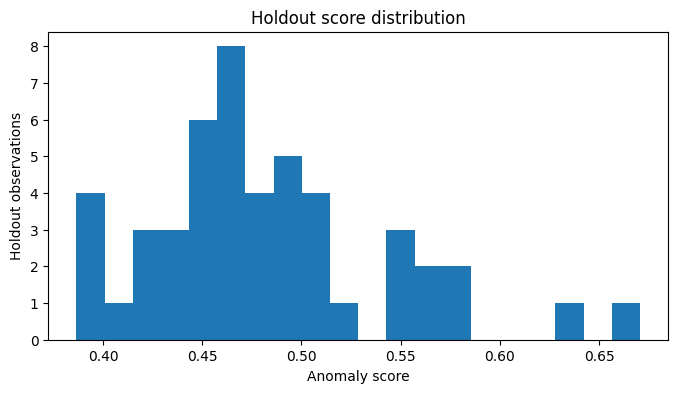

In [5]:
fig, ax = plt.subplots(figsize=(8,4))
ax.hist(test.score, bins=20)
ax.set(xlabel='Anomaly score', ylabel='Holdout observations', title='Holdout score distribution')
plt.show()

## Export and verify
Save a newly reproduced model in reproduced_models, leaving the submitted original untouched. Compare predictions with the original model on the same holdout data.

In [6]:
output = ROOT / 'reproduced_models'
output.mkdir(exist_ok=True)
path = output / (SLUG + '.joblib')
joblib.dump(model, path)
loaded = joblib.load(path)
original = joblib.load(ROOT / 'models' / (SLUG + '.joblib'))
assert np.array_equal(loaded.predict(X), model.predict(X))
assert np.array_equal(original.predict(X), loaded.predict(X))
assert np.allclose(original.score_samples(X), loaded.score_samples(X))
print('Saved:', path.name)
print('Original and reproduced holdout predictions and scores match.')
test.to_csv(output / (SLUG + '_holdout.csv'), index=False)
print('Example prediction:', loaded.predict(X[:1])[0], '(-1 anomaly, +1 normal)')

Saved: united_kingdom.joblib
Original and reproduced holdout predictions and scores match.
Example prediction: 1 (-1 anomaly, +1 normal)


## Interpretation and limitations
This model detects unusual combinations of temperature, precipitation and soil wetness. It does not establish causal relationships, forecast weather, or test long-term trend significance. Results are limited by the coarse grid and absence of labelled anomalies. Source: https://power.larc.nasa.gov/ .